# Building models to compare two treatments for prostatic cancer

To compare two treatments we first look for the prognostic variables that explain the survival, and only then we add the treatment to the model. With few variables we can fit all the possible models.

The data are the survival times, in months, of 38 patients with prostatic cancer, with their age, serum haemoglobin (`shb`), size of the tumour (`size`) and Gleason index (`index`).

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import chi2
from lifelines import CoxPHFitter, KaplanMeierFitter

In [2]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
opt_color   = '#E69F00'
ref_color   = '#333333'

## The data

In [3]:
DatOriginal = pd.read_csv("data/prostatic_cancer_treatments.dat", sep=r"\s+")

In [4]:
DatOriginal.head()

,patient,treatment,time,status,age,shb,size,index
0,1,1,65,0,67,13.4,34,8
1,2,2,61,0,60,14.6,4,10
2,3,2,60,0,77,15.6,3,8
3,4,1,58,0,64,16.2,6,9
4,5,2,51,0,65,14.1,21,9


Treatment 1 means that the patient was treated with a placebo and 2 means that was treated with DES.

In [5]:
DatOriginal.groupby('treatment').agg(patients=('time', 'size'), deaths=('status', 'sum'))

,patients,deaths
treatment,,
1,18,5
2,20,1


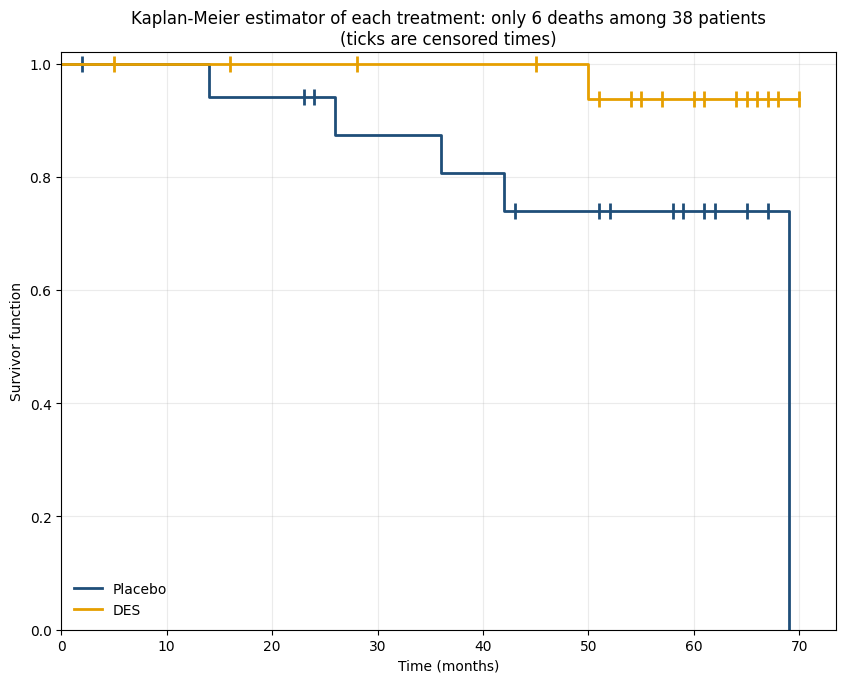

In [6]:
fig, ax = plt.subplots(figsize=(10, 7.5))
for (treatment, DatGroup), color, label in zip(DatOriginal.groupby('treatment'), [line_color, opt_color], ['Placebo', 'DES']):
    kmf = KaplanMeierFitter().fit(DatGroup['time'], event_observed=DatGroup['status'])
    surv = kmf.survival_function_.iloc[:, 0]
    censored = kmf.event_table.index[kmf.event_table['censored'] > 0]
    ax.step(surv.index, surv, where='post', color=color, lw=2, label=label)
    ax.plot(censored, surv.loc[censored], '|', color=color, markersize=11, markeredgewidth=2)

ax.set_xlabel('Time (months)')
ax.set_ylabel('Survivor function')
ax.set_xlim(0, None)
ax.set_ylim(0, 1.02)
ax.set_title(f"Kaplan-Meier estimator of each treatment: only {DatOriginal['status'].sum()} deaths among {len(DatOriginal)} patients\n(ticks are censored times)")
ax.legend(loc='lower left', frameon=False)
ax.grid(True, alpha=0.25)

## All the possible models

Function that calculates the test statistic and $P$-value to compare two nested models based on the log-likelihood ratio test.

In [7]:
def LoglikeRatioTest(minus2loglike_model1, minus2loglike_model2, df_model1, df_model2):
    # model1 must be nested in model2, i.e. model2 has more variables than model1
    test_statistic = minus2loglike_model1 - minus2loglike_model2
    p_value = chi2.sf(test_statistic, df_model2-df_model1)
    return test_statistic, p_value

The data only has four prognostic variables: age, shb, size, and index.

We can create a model for each possible combination of these variables, i.e., we can build 16 models.

In [8]:
formulas = [
    'age', 'shb', 'size', 'index',
    'age+shb', 'age+size', 'age+index', 'shb+size', 'shb+index', 'size+index',
    'age+shb+size', 'age+shb+index', 'age+size+index', 'shb+size+index',
    'age+shb+size+index'
]

MinusTwoLogLike = []
Aic = []
DegreesFreedom = []

for i,f in enumerate(formulas):

    cph = CoxPHFitter()
    Model = cph.fit(DatOriginal, 'time', 'status', formula=f)

    if i==0:
        _ = -2*Model.log_likelihood_ + Model.log_likelihood_ratio_test().test_statistic
        MinusTwoLogLike.append(_)
        DegreesFreedom.append(0)
        Aic.append(_)

    MinusTwoLogLike.append(-2*Model.log_likelihood_)
    DegreesFreedom.append(len(Model.summary))
    Aic.append(Model.AIC_partial_)

formulas.insert(0, 'None')

ModelSummary = pd.DataFrame({'formula': formulas, '-2log-L': MinusTwoLogLike, 'AIC': Aic, 'df': DegreesFreedom})

We can simply select the model with the smallest AIC.

In [9]:
ModelSummary[ModelSummary['AIC'] == ModelSummary['AIC'].min()]

,formula,-2log-L,AIC,df
10,size+index,23.533263,27.533263,2


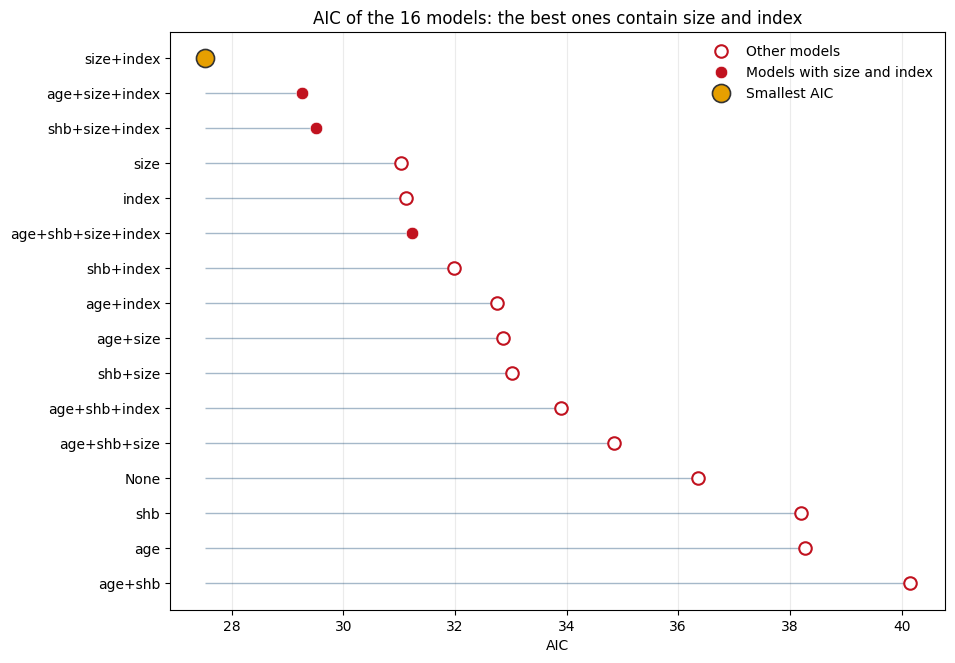

In [10]:
Sorted = ModelSummary.sort_values('AIC', ascending=False).reset_index(drop=True)
HasBoth = Sorted['formula'].str.contains('size') & Sorted['formula'].str.contains('index')

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.hlines(Sorted.index, Sorted['AIC'].min(), Sorted['AIC'], color=line_color, lw=1, alpha=0.4)
ax.plot(Sorted.loc[~HasBoth, 'AIC'], Sorted.index[~HasBoth], 'o', markerfacecolor='white', markersize=9,
        markeredgecolor=point_color, markeredgewidth=1.5, label='Other models')
ax.plot(Sorted.loc[HasBoth, 'AIC'], Sorted.index[HasBoth], 'o', color=point_color, markersize=9, markeredgecolor='white',
        markeredgewidth=0.5, label='Models with size and index')
ax.plot(Sorted['AIC'].iloc[-1], Sorted.index[-1], 'o', color=opt_color, markersize=13, markeredgecolor=ref_color,
        markeredgewidth=1.2, label='Smallest AIC', zorder=5)

ax.set_yticks(Sorted.index, Sorted['formula'])
ax.set_xlabel('AIC')
ax.set_title('AIC of the 16 models: the best ones contain size and index')
ax.legend(loc='upper right', frameon=False)
ax.grid(True, axis='x', alpha=0.25)

## A strategy for several variables

Alternatively, we can follow the next strategy if we have several variables.

1. First we fit models that contain each of the variables at a time. The variables that appear important, compared to the Null model are then consider in the subsequent step.

In [11]:
ModelSummary.round(3)

,formula,-2log-L,AIC,df
0,None,36.349,36.349,0
1,age,36.269,38.269,1
2,shb,36.196,38.196,1
3,size,29.042,31.042,1
4,index,29.127,31.127,1
5,age+shb,36.151,40.151,2
6,age+size,28.854,32.854,2
7,age+index,28.760,32.760,2
8,shb+size,29.019,33.019,2
9,shb+index,27.981,31.981,2


In [12]:
PValues = []

for i in [1,2,3,4]:
    _, Pvalue = LoglikeRatioTest(ModelSummary.loc[0]['-2log-L'], ModelSummary.loc[i]['-2log-L'], 0, ModelSummary.loc[i]['df'])
    PValues.append(Pvalue)

np.round(PValues,3)

array([0.778, 0.696, 0.007, 0.007])

From the previous $P$-values we deduce that only size and index appear to be important.

2. The variables that appear to be important from step 1 are then fitted together. In the presence of certain variables, others may cease to be important. Those that do not lead to a significant increase in the value of $-2\log \hat{L}$ when omitted can be discarded.

In [13]:
# Comparing model size+index against model size, i.e. omitting index
np.round(LoglikeRatioTest(
    ModelSummary.loc[3]['-2log-L'],
    ModelSummary.loc[10]['-2log-L'],
    ModelSummary.loc[3]['df'],
    ModelSummary.loc[10]['df']
),3)
# index should not be omitted

array([5.508, 0.019])

In [14]:
# Comparing model size+index against model index, i.e. omitting size
np.round(LoglikeRatioTest(
    ModelSummary.loc[4]['-2log-L'],
    ModelSummary.loc[10]['-2log-L'],
    ModelSummary.loc[4]['df'],
    ModelSummary.loc[10]['df']
),3)
# size should not be omitted

array([5.594, 0.018])

We can deduce from this analysis that both variables are needed.

3. Variables that were not important on their own may become important in the presence of others. We added such variables one at a time to our model. Those that reduce $-2\log\hat{L}$ significantly are retained in the model.

In [15]:
# Comparing model size+index against model size+index+age, i.e. adding age
np.round(LoglikeRatioTest(
    ModelSummary.loc[10]['-2log-L'],
    ModelSummary.loc[13]['-2log-L'],
    ModelSummary.loc[10]['df'],
    ModelSummary.loc[13]['df']
),3)
# age should not be added

array([0.264, 0.607])

In [16]:
# Comparing model size+index against model size+index+shb, i.e. adding shb
np.round(LoglikeRatioTest(
    ModelSummary.loc[10]['-2log-L'],
    ModelSummary.loc[14]['-2log-L'],
    ModelSummary.loc[10]['df'],
    ModelSummary.loc[14]['df']
),3)
# shb should not be added

array([0.025, 0.874])

## The treatment effect

We now consider the treatment effect, and observe if it is significant.

In [17]:
def FitShowingWarnings(formula):
    # Fit a Cox model and print the warnings of the fit instead of sending them to the error stream
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model = CoxPHFitter().fit(DatOriginal, 'time', 'status', formula=formula)
    for w in caught:
        print(f'{w.category.__name__}: {str(w.message).strip().splitlines()[0]}')
    return model

In [18]:
ModelTreat = FitShowingWarnings('size+index+C(treatment)')

np.round(LoglikeRatioTest(
    ModelSummary.loc[10]['-2log-L'],
    -2*ModelTreat.log_likelihood_,
    ModelSummary.loc[10]['df'],
    len(ModelTreat.summary)
),3)

array([0.961, 0.327])

If the possibility of interactions between the treatment and other explanatory variables has not been discounted, these must be considered before the treatment effect can be interpreted

In [19]:
ModelTsize = FitShowingWarnings('size+index+C(treatment)+size*C(treatment)')

np.round(LoglikeRatioTest(
    ModelSummary.loc[10]['-2log-L'],
    -2*ModelTsize.log_likelihood_,
    ModelSummary.loc[10]['df'],
    len(ModelTsize.summary)
),3)

array([2.705, 0.259])

In [20]:
ModelTindex = FitShowingWarnings('size+index+C(treatment)+index*C(treatment)')

np.round(LoglikeRatioTest(
    ModelSummary.loc[10]['-2log-L'],
    -2*ModelTindex.log_likelihood_,
    ModelSummary.loc[10]['df'],
    len(ModelTindex.summary)
),3)

array([1.762, 0.414])

In [21]:
ModelTsizeTindex = FitShowingWarnings('size+index+C(treatment)+size*C(treatment)+index*C(treatment)')

np.round(LoglikeRatioTest(
    ModelSummary.loc[10]['-2log-L'],
    -2*ModelTsizeTindex.log_likelihood_,
    ModelSummary.loc[10]['df'],
    len(ModelTsizeTindex.summary)
),3)

array([3.594, 0.309])

We conclude that treatment with DES does not appear to affect the hazard of death.

## Overfitted models

Notice that we receive a warning message of not convergence of Newton-Raphson. If we plot the models, we will observe that they are overfitted. So we should not include the mixed terms. These is because in the data there are only 6 confirmed deaths.

In [22]:
DatOriginal.status.sum()

np.int64(6)

Estimated coefficients with their 95% confidence intervals. The intervals of the terms with the treatment are enormous: the data cannot estimate them.

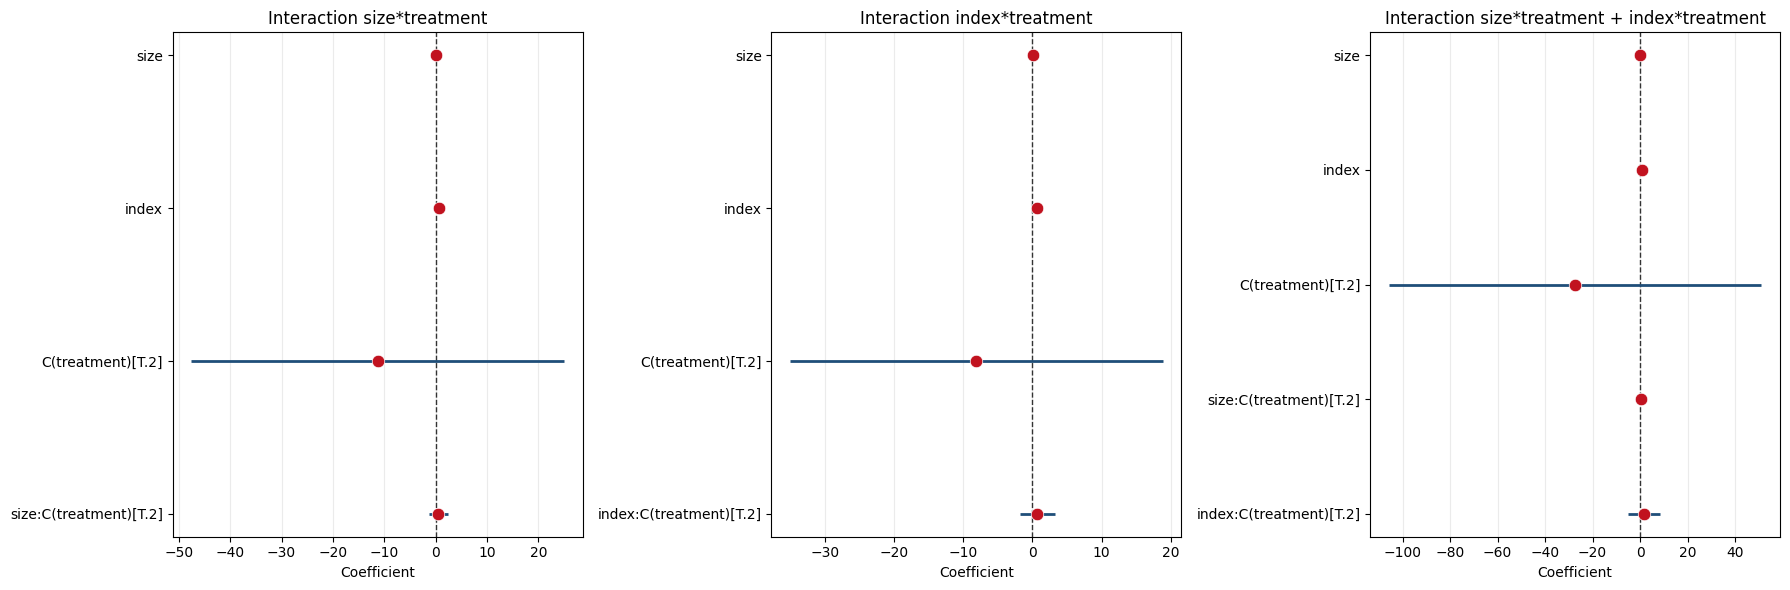

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
models = [(ModelTsize, 'size*treatment'), (ModelTindex, 'index*treatment'), (ModelTsizeTindex, 'size*treatment + index*treatment')]
for ax, (model, name) in zip(axes, models):
    summary = model.summary
    position = np.arange(len(summary))[::-1]
    ax.axvline(0, color=ref_color, lw=1, ls='--')
    ax.hlines(position, summary['coef lower 95%'], summary['coef upper 95%'], color=line_color, lw=2)
    ax.plot(summary['coef'], position, 'o', color=point_color, markersize=9, markeredgecolor='white', markeredgewidth=0.5)
    ax.set_yticks(position, summary.index)
    ax.set_xlabel('Coefficient')
    ax.set_title(f'Interaction {name}')
    ax.grid(True, axis='x', alpha=0.25)
plt.tight_layout()